# Notebook 3: Exploratory Data Analysis (EDA)
## Project: Crop Stress and Irrigation Priority Decision Support System
**Objective:** Visualize relationships between weather, soil moisture, crop water stress, and irrigation priority using simple, clear Matplotlib and Seaborn graphs.

### Step 1: Import Required Libraries
We import Pandas, NumPy, Matplotlib, and Seaborn. No complex or 3D visualization libraries are used.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load the Clean Preprocessed Dataset

In [2]:
try:
    df = pd.read_csv("data/processed/krishijal_ml_clean.csv")
    print("Loaded data/processed/krishijal_ml_clean.csv")
except:
    try:
        df = pd.read_csv("krishijal_ml_clean.csv")
        print("Loaded krishijal_ml_clean.csv from current directory")
    except:
        df = pd.read_csv("data/processed/krishijal_master_dataset.csv")
        print("Loaded data/processed/krishijal_master_dataset.csv")

Loaded krishijal_ml_clean.csv from current directory


### Step 3: Statistical Summary of Features

In [3]:
df.describe()

,cwsi,effective_soil_wetness,water_deficit,ndvi,et0,etc,temperature,rainfall,humidity,stress_level_code,irrigation_priority_index
count,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000
mean,0.087087,0.630155,0.259997,0.672605,4.086335,4.024665,25.745818,4.557325,70.246515,0.394349,21.699970
std,0.140770,0.170067,0.613972,0.176317,1.145563,1.292759,5.535395,9.270983,16.791530,0.764187,13.942208
min,0.000000,0.130000,0.000000,0.186000,0.100000,0.090000,-16.010000,0.000000,16.610000,0.000000,0.800000
25%,0.000000,0.495000,0.000000,0.580000,3.340000,3.100000,23.582500,0.050000,60.872500,0.000000,10.000000
50%,0.000000,0.642000,0.000000,0.724000,4.130000,3.970000,26.570000,1.030000,75.280000,0.000000,19.000000
75%,0.156000,0.765000,0.000000,0.783000,4.790000,4.900000,28.840000,5.640000,83.217500,1.000000,28.875000
max,0.764000,0.990000,4.950000,0.880000,7.540000,8.180000,40.990000,262.610000,96.070000,3.000000,73.700000


### Graph 1: Distribution of Crop Water Stress Index (CWSI)
CWSI measures plant water stress from 0 (no stress) to 1 (complete transpiration cessation).

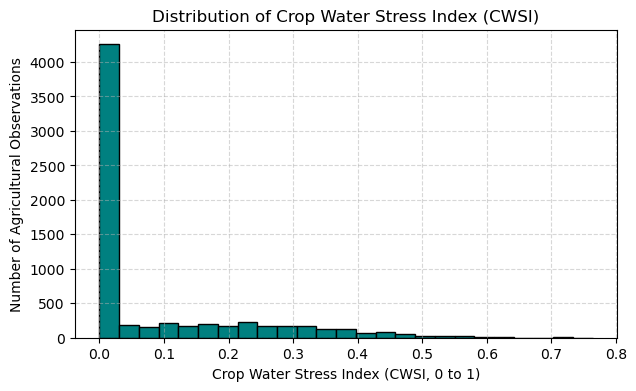

In [4]:
plt.figure(figsize=(7, 4))
plt.hist(df["cwsi"], bins=25, color="teal", edgecolor="black")
plt.title("Distribution of Crop Water Stress Index (CWSI)")
plt.xlabel("Crop Water Stress Index (CWSI, 0 to 1)")
plt.ylabel("Number of Agricultural Observations")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Graph 2: Crop Stress Severity Level Counts
Bar chart displaying the frequency of each stress category (0: Low, 1: Moderate, 2: High, 3: Severe).

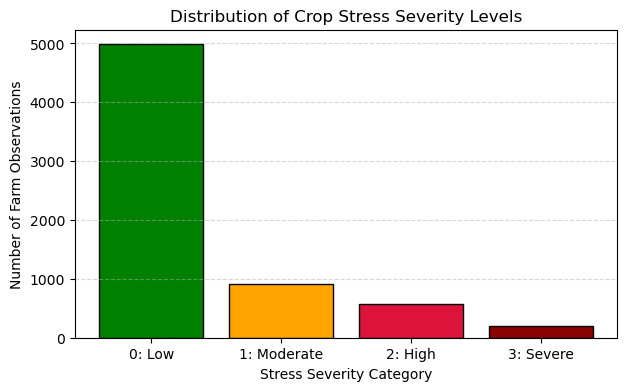

In [5]:
plt.figure(figsize=(7, 4))
stress_counts = df["stress_level_code"].value_counts().sort_index()
stress_labels = ["0: Low", "1: Moderate", "2: High", "3: Severe"]

plt.bar(stress_labels, stress_counts.values, color=["green", "orange", "crimson", "darkred"], edgecolor="black")
plt.title("Distribution of Crop Stress Severity Levels")
plt.xlabel("Stress Severity Category")
plt.ylabel("Number of Farm Observations")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Graph 3: Distribution of Irrigation Priority Index (IPI)
Histogram showing the range and spread of the continuous Irrigation Priority Index (0 to 100).

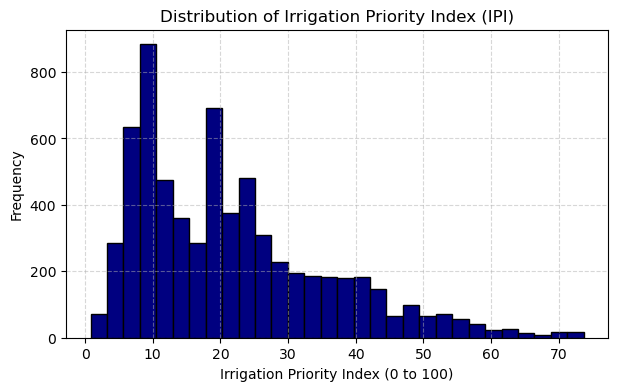

In [6]:
plt.figure(figsize=(7, 4))
plt.hist(df["irrigation_priority_index"], bins=30, color="navy", edgecolor="black")
plt.title("Distribution of Irrigation Priority Index (IPI)")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Graph 4: Soil Moisture vs. Crop Stress Levels
Box plot showing how effective soil moisture drops as crop stress transitions from Low to Severe.

/var/folders/37/qg9rk4ks5ll878248d8dyggh0000gn/T/ipykernel_896/1601118560.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="stress_level_code", y="effective_soil_wetness", data=df, palette="YlGnBu")


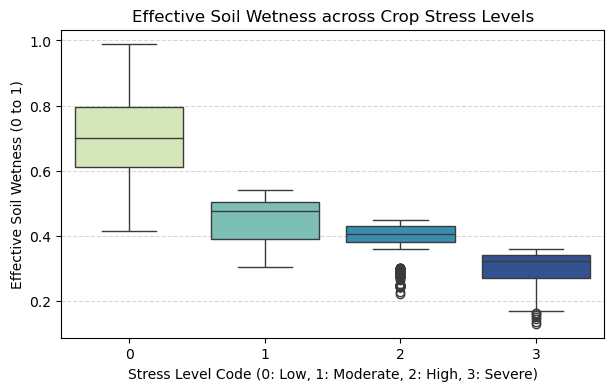

In [7]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="stress_level_code", y="effective_soil_wetness", data=df, palette="YlGnBu")
plt.title("Effective Soil Wetness across Crop Stress Levels")
plt.xlabel("Stress Level Code (0: Low, 1: Moderate, 2: High, 3: Severe)")
plt.ylabel("Effective Soil Wetness (0 to 1)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

### Graph 5: Relationship between CWSI and Daily Water Deficit
Scatter plot showing how higher water deficit strongly correlates with severe crop water stress.

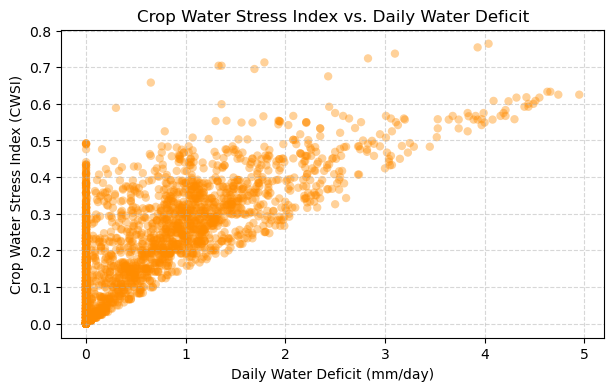

In [8]:
plt.figure(figsize=(7, 4))
plt.scatter(df["water_deficit"], df["cwsi"], alpha=0.4, color="darkorange", edgecolors="none")
plt.title("Crop Water Stress Index vs. Daily Water Deficit")
plt.xlabel("Daily Water Deficit (mm/day)")
plt.ylabel("Crop Water Stress Index (CWSI)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Graph 6: Correlation Heatmap of Agricultural Features
Heatmap displaying pairwise linear correlations between all predictors and targets.

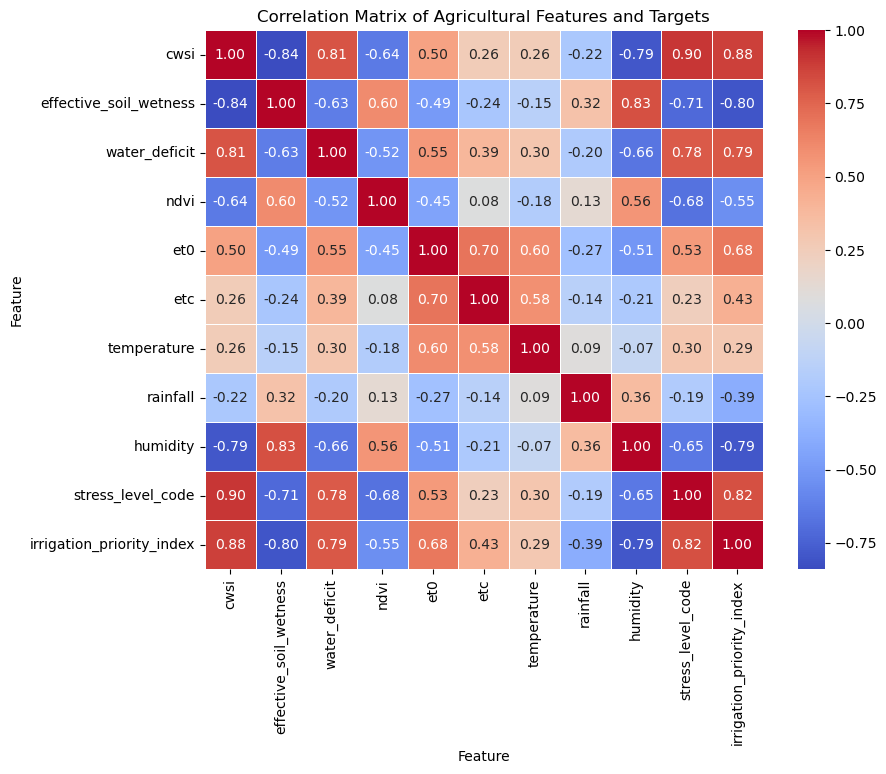

In [9]:
plt.figure(figsize=(9, 7))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix of Agricultural Features and Targets")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

### Step 4: Summary of EDA Findings
1. **Soil Moisture Depletion:** Severe crop stress strictly occurs when effective soil wetness falls below 0.35.
2. **Deficit Link:** Daily water deficit has a strong positive correlation with CWSI ($r > 0.70$) and Irrigation Priority Index.
3. **Model Suitability:** Strong linear and non-linear patterns indicate that **Logistic Regression, Decision Trees, and Random Forests** are ideal for classification, while **Linear Regression, Decision Tree Regressor, and Random Forest Regressors** are suited for priority scoring.
4. Next, we proceed to Model Training in `04_model_training.ipynb`.